In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv("8-fraud_detection.csv")

In [3]:
df

,transaction_amount,transaction_risk_score,is_fraud
0,1.879910,-1.485035,0
1,0.377083,-2.238585,0
2,1.354312,-2.664638,0
3,-0.509843,-1.502950,0
4,0.863561,-1.906364,0
...,...,...,...
9995,1.066698,-0.548159,0
9996,1.058723,-0.933768,0
9997,0.995099,-0.541924,0
9998,1.758594,-1.549612,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   transaction_amount      10000 non-null  float64
 1   transaction_risk_score  10000 non-null  float64
 2   is_fraud                10000 non-null  int64  
dtypes: float64(2), int64(1)
memory usage: 234.5 KB


In [5]:
df["is_fraud"].value_counts()

is_fraud
0    9846
1     154
Name: count, dtype: int64

In [6]:
df["is_fraud"].unique()

array([0, 1])

In [7]:
# imbalanced dataset, feature engineering açısından bakıldığında 0 azaltılabilir veya 1 artırılabilir.

In [8]:
X = df.drop("is_fraud", axis=1)
y = df["is_fraud"]

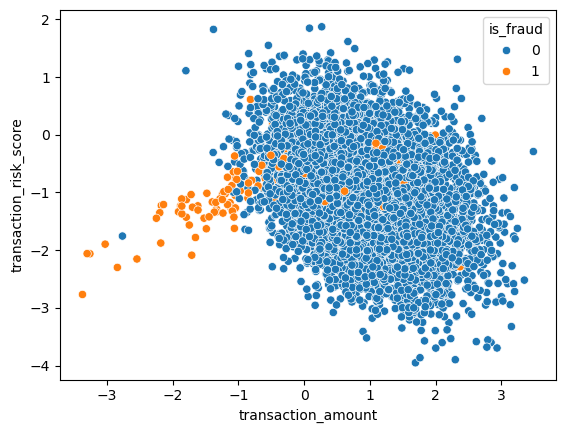

In [9]:
sns.scatterplot(x=X["transaction_amount"], y=X["transaction_risk_score"], hue=y)
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=15)

In [12]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [13]:
penalty = ["l1", "l2", "elasticnet"]
C_values = [100,10,1,0.1,0.01]
solver = ["newton-cg", "lbfgs", "sag", "saga", "newton-cholesky", "liblinear"]
class_weight = [{0:w, 1:y} for w in [1,10,50,100] for y in [1,10,50,100]]

In [14]:
class_weight

[{0: 1, 1: 1},
 {0: 1, 1: 10},
 {0: 1, 1: 50},
 {0: 1, 1: 100},
 {0: 10, 1: 1},
 {0: 10, 1: 10},
 {0: 10, 1: 50},
 {0: 10, 1: 100},
 {0: 50, 1: 1},
 {0: 50, 1: 10},
 {0: 50, 1: 50},
 {0: 50, 1: 100},
 {0: 100, 1: 1},
 {0: 100, 1: 10},
 {0: 100, 1: 50},
 {0: 100, 1: 100}]

In [15]:
params = dict(penalty=penalty, C=C_values, solver=solver, class_weight=class_weight)

In [16]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [17]:
cv = StratifiedKFold()

In [18]:
grid = GridSearchCV(model, param_grid=params, scoring="accuracy", cv=cv)

In [19]:
import warnings
warnings.filterwarnings("ignore")

In [20]:
grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=LogisticRegression(),
             param_grid={'C': [100, 10, 1, 0.1, 0.01],
                         'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10},
                                          {0: 1, 1: 50}, {0: 1, 1: 100},
                                          {0: 10, 1: 1}, {0: 10, 1: 10},
                                          {0: 10, 1: 50}, {0: 10, 1: 100},
                                          {0: 50, 1: 1}, {0: 50, 1: 10},
                                          {0: 50, 1: 50}, {0: 50, 1: 100},
                                          {0: 100, 1: 1}, {0: 100, 1: 10},
                                          {0: 100, 1: 50}, {0: 100, 1: 100}],
                         'penalty': ['l1', 'l2', 'elasticnet'],
                         'solver': ['newton-cg', 'lbfgs', 'sag', 'saga',
                                    'newton-cholesky', 'liblinear']},
             scoring='accuracy')

In [21]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [22]:
y_pred = grid.predict(X_test)

In [23]:
score = accuracy_score(y_test, y_pred)
print("score:", score)
print(classification_report(y_test, y_pred))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))

score: 0.9893333333333333
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2951
           1       0.87      0.41      0.56        49

    accuracy                           0.99      3000
   macro avg       0.93      0.70      0.78      3000
weighted avg       0.99      0.99      0.99      3000

confusion matrix:
 [[2948    3]
 [  29   20]]


In [24]:
# roc and auc

In [25]:
# roc curve --> a classification model's performance across different threshold values.(remaind that default: 0.5
# auc --> area under (that) curve

In [34]:
model_prob = grid.predict_proba(X_test)

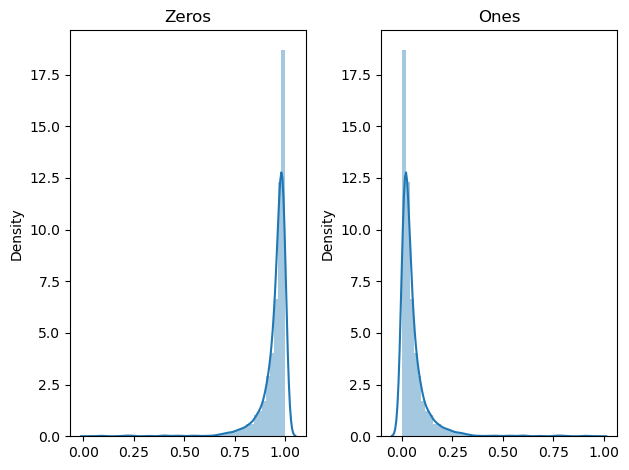

In [41]:
plt.subplot(1,2,1)
sns.distplot(x=model_prob[:,0])
plt.title("Zeros")
plt.subplot(1,2,2)
sns.distplot(x=model_prob[:,1])
plt.title("Ones")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import roc_curve, roc_auc_score

In [45]:
model_prob_1 = model_prob[:,1]

In [47]:
model_auc = roc_auc_score(y_test, model_prob_1)

In [48]:
model_auc

np.float64(0.779196260001798)

In [56]:
fpr, tpr, thresholds = roc_curve(y_test, model_prob_1)

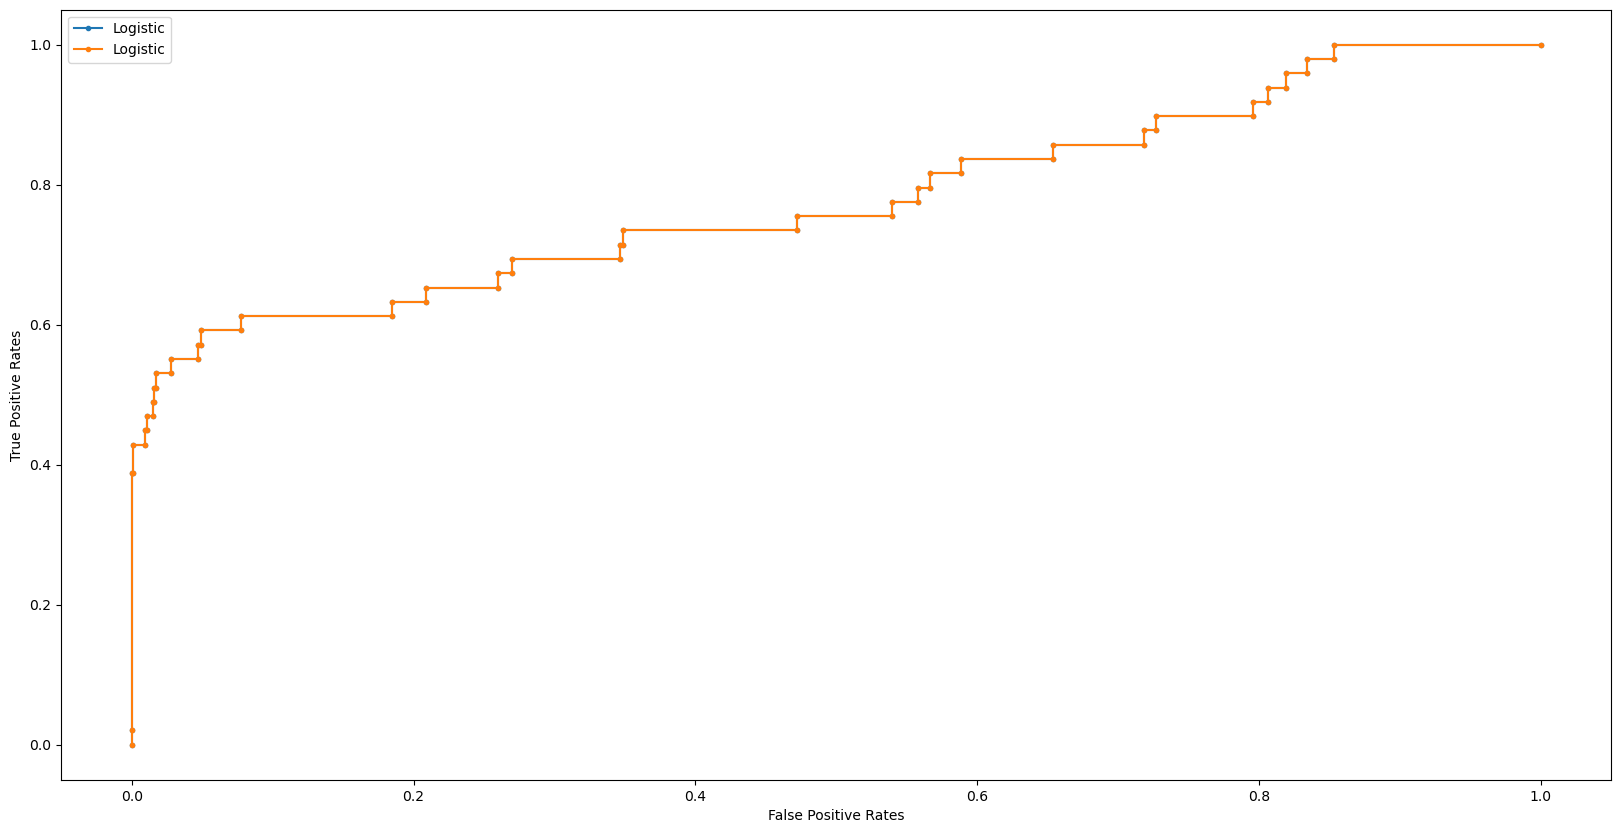

In [57]:
plt.plot(fpr, tpr, marker=".", label="Logistic")
plt.xlabel("False Positive Rates")
plt.ylabel("True Positive Rates")
plt.legend()
plt.show()

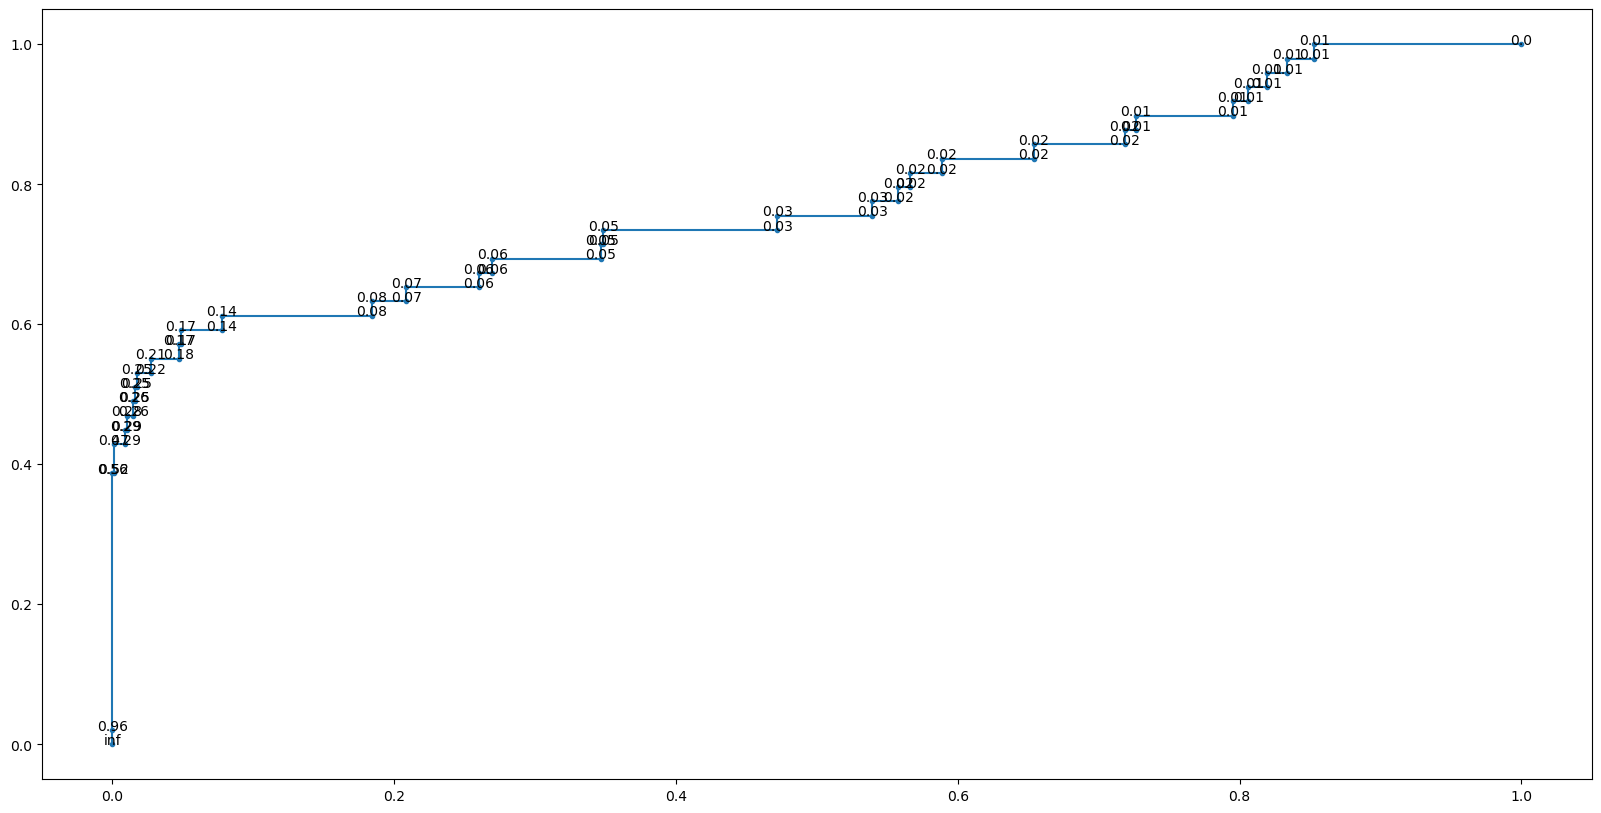

In [58]:
fig, ax = plt.subplots(figsize=(20,10))

ax.plot(fpr, tpr, marker=".", label="Logistic")

for fpr, tpr, threshold in zip(fpr, tpr, thresholds):
    ax.annotate(f"{np.round(threshold, 2)}", (fpr, tpr), ha="center")
plt.show()

In [61]:
custom_threshold = 0.2

y_pred_custom = (model_prob_1 >= custom_threshold).astype(int)

print(confusion_matrix(y_test, y_pred_custom))

[[2854   97]
 [  22   27]]


In [60]:
y_pred_custom

array([0, 0, 0, ..., 0, 0, 1])

In [69]:
(model_prob_1 >= custom_threshold).astype(int)

array([0, 0, 0, ..., 0, 0, 1])